# Chapter 7: Explore vs Exploit: Bandits from Scratch

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Explore vs Exploit: Bandits from Scratch](https://books.sugiv.fyi/lift/explore-exploit.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
# Setup for the whole chapter. Hidden from the page; everything is seeded.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)


def glue_num(name, value):
    """Glue a number for inline use in the text (as a plain float)."""
    glue(name, float(value), display=False)

from sim import parlo, style

style.apply()
pd.set_option("display.precision", 3)

NAMES = list(parlo.REMINDERS)
RATES = np.array(list(parlo.REMINDERS.values()))
HORIZON, RUNS = 10_000, 200

ab = parlo.simulate(parlo.fixed_split, RATES, HORIZON, RUNS, seed=1)
ts = parlo.simulate(parlo.thompson, RATES, HORIZON, RUNS, seed=1)

ab_lost = ab.regret[:, -1].mean()
ts_lost = ts.regret[:, -1].mean()
glue_num("ab_lost", ab_lost)
glue_num("ts_lost", ts_lost)
glue_num("saving_pct", 100 * (1 - ts_lost / ab_lost))
glue_num("ts_best_share", 100 * ts.share_of_best()[-1000:].mean())

Here's the finding first. Parlo wants to know which of four streak reminders brings learners back. If I run a classic four-way A/B test for 10,000 sends, I give up about **163 returning learners** while the test runs, because three quarters of the traffic goes to messages that aren't the best. If I let a **Thompson sampling bandit** pick the message for each send instead, I give up about **62**. That's **62% fewer lost learners**, and by the end the bandit is sending the best message **84%** of the time.

The catch is that the bandit tells me less about the losing messages. Knowing when that trade is worth it is the real skill, and it's what this chapter is about.

> **Note**
>
> **Parlo** and **Juno** are fictional. Parlo is a language-learning app, and Juno is its AI tutor. The numbers come from a seeded simulator in `lift/sim/parlo.py`, so you can rerun every result and get exactly the same answer.

## Bandits in plain English

You have four reminder messages. Every time a learner's streak is about to break, you send one of them. Each send does two jobs at once:

- It's a chance to **learn** which message works best.
- It's a chance to **earn**, by using the message that looks best so far.

Those two jobs pull against each other. If you only earn, you might lock onto a message that got lucky early. If you only learn, you keep wasting sends on messages you already suspect are worse. A **multi-armed bandit** is any strategy that balances the two, send by send.

The name comes from slot machines (one-armed bandits). Picture a row of four machines with different, unknown payout rates. You have a fixed number of coins. Which machine do you play next?

Five words carry the whole chapter:

| Term | In Parlo terms |
|---|---|
| **Arm** | One of the four reminder messages |
| **Reward** | 1 if the learner came back and did a lesson, 0 if not |
| **Explore** | Send a message to learn more about it |
| **Exploit** | Send the message that currently looks best |
| **Regret** | Returns you gave up by not always sending the true best message |

Regret is the scoreboard. A perfect strategy that somehow knew the best message from day one would have zero regret. Every real strategy pays some regret to learn; good strategies pay less.

## The case: four reminders

These are Parlo's four messages and their *true* return rates. In real life nobody knows these numbers. The simulator does, which is exactly what lets us score each strategy.

In [3]:
pd.DataFrame({
    "Message": NAMES,
    "Example text": [
        "Time for your Spanish lesson.",
        "Your 12-day streak ends tonight.",
        "Juno saved a 3-minute lesson for you.",
        "You learned 48 words this week.",
    ],
    "True return rate": RATES,
})

,Message,Example text,True return rate
0,Plain nudge,Time for your Spanish lesson.,0.090
1,Streak at risk,Your 12-day streak ends tonight.,0.105
2,Juno says hi,Juno saved a 3-minute lesson for you.,0.120
3,Progress recap,You learned 48 words this week.,0.100


"Juno says hi" is the best at 12%. The worst, "Plain nudge", is at 9%. The gap between best and second best is only 1.5 points, which is realistic and makes the problem hard.

## The A/B test way

The classic approach splits traffic evenly, waits, and then compares. Here's a single 10,000-send test, analysed with Pingouin's chi-squared test of independence.

In [4]:
one = pd.DataFrame({
    "message": np.array(NAMES)[ab.choices[0]],
    "came_back": ab.rewards[0],
})
expected, observed, stats = pg.chi2_independence(one, x="message", y="came_back")

summary = one.groupby("message")["came_back"].agg(sends="size", return_rate="mean")
summary.loc[NAMES]

,sends,return_rate
message,,
Plain nudge,2454,0.094
Streak at risk,2529,0.106
Juno says hi,2524,0.127
Progress recap,2493,0.096


In [5]:
stats.query("test == 'pearson'")[["chi2", "dof", "pval", "cramer"]]

,chi2,dof,pval,cramer
0,17.923,3.0,4.563e-04,0.042


In [6]:
glue_num("ab_pval", stats.query("test == 'pearson'")["pval"].iloc[0])

The test says the messages differ (p = 0.0005). It doesn't say which one wins by a clear margin, and with roughly 2,500 sends per message the confidence intervals of the top two overlap. Meanwhile 7,500 of the 10,000 sends went to messages that aren't the best. That's where the 163 lost returns come from.

## The answer in 10 lines: Thompson sampling

Here's the bandit. It needs nothing beyond numpy.

In [7]:
rng = np.random.default_rng(42)
wins = np.zeros(4)    # learners who came back, per message
sends = np.zeros(4)   # times each message was sent

for _ in range(10_000):
    guesses = rng.beta(1 + wins, 1 + sends - wins)   # one plausible rate per message
    arm = np.argmax(guesses)                         # send the best guess
    came_back = rng.random() < RATES[arm]            # the world answers
    sends[arm] += 1
    wins[arm] += came_back

pd.DataFrame({"message": NAMES, "sends": sends.astype(int), "observed rate": wins / sends})

,message,sends,observed rate
0,Plain nudge,215,0.065
1,Streak at risk,736,0.095
2,Juno says hi,7833,0.124
3,Progress recap,1216,0.101


The idea in one sentence: **for each message, draw a random guess of its return rate from what you've seen so far, then send the message with the highest guess.**

- A message you've barely tried has a wide range of plausible rates, so it sometimes draws a high guess and gets explored.
- A message you've tried a lot has a narrow range, so its guess sits close to its observed rate.
- As evidence piles up, the best message wins the draw more and more often, and exploration fades out by itself.

There's no exploration rate to tune and no "end of test" to decide on.

<details>
<summary><b>Under the hood: why a Beta distribution?</b></summary>

If a message has been sent $n$ times and $s$ learners came back, then, starting from a flat prior, our belief about its true rate $p$ is

$$p \sim \mathrm{Beta}(1 + s,\ 1 + n - s).$$

Its mean is $(1+s)/(2+n)$, close to the observed rate, and its spread shrinks roughly like $1/\sqrt{n}$. Thompson sampling draws one $p$ from each message's Beta and plays the largest. The chance it picks a message equals the probability, given the data so far, that the message is the best. That's why it explores exactly as much as the uncertainty justifies.

</details>

## Watch it think: the first 20 sends

Before running thousands of simulations, it helps to watch a single run one send at a time. Each row shows the guess Thompson drew for every message, which one it picked, and whether the learner came back.

In [8]:
trace = parlo.trace_thompson(RATES, steps=20, seed=3)
pd.DataFrame([
    {"send": r["step"], **{n: g for n, g in zip(NAMES, r["draws"])},
     "picked": NAMES[r["picked"]], "came back": "yes" if r["came_back"] else "no"}
    for r in trace
]).set_index("send")

,Plain nudge,Streak at risk,Juno says hi,Progress recap,picked,came back
send,,,,,,
1,0.266,0.179,0.750,0.866,Progress recap,no
2,0.545,0.995,0.962,0.738,Streak at risk,no
3,0.247,0.153,0.107,0.167,Plain nudge,no
4,0.047,0.560,0.522,0.508,Streak at risk,no
5,0.425,0.700,0.936,0.217,Juno says hi,no
6,0.174,0.274,0.360,0.536,Progress recap,no
7,0.479,0.129,0.312,0.267,Plain nudge,yes
8,0.621,0.403,0.092,0.067,Plain nudge,no
9,0.717,0.109,0.334,0.329,Plain nudge,no


Early on, the guesses are all over the place, because with no data any rate between 0 and 1 is plausible. So the picks jump between messages. That's exploration, and nobody had to program it.

Look at the "came back" column: in 20 sends, only one learner returned. With return rates around 10%, that's normal, and it's the heart of why this problem is hard. Each "no" pulls a message's guesses down a little, and each "yes" pulls them up a lot. By send 20 the guesses have already shrunk from anywhere in 0 to 1 to mostly below 0.5, but they're nowhere near precise. It takes hundreds of sends before the four messages separate. That's why we judge strategies over thousands of sends, not twenty.

## Regret: the price of learning

Now the fair comparison: 200 independent worlds, 10,000 sends each, the same four messages. The line is the average cumulative regret, and the band covers the middle 80% of worlds.

In [9]:
glue_num("runs", RUNS)

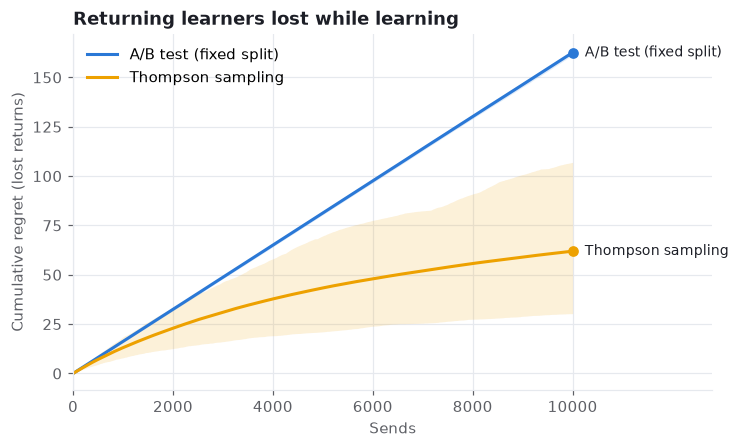

In [10]:
def regret_band(ax, result, label):
    colour = style.STRATEGY_COLOURS[label]
    r = result.regret
    x = np.arange(1, r.shape[1] + 1)
    ax.fill_between(x, np.percentile(r, 10, axis=0), np.percentile(r, 90, axis=0),
                    color=colour, alpha=0.15, linewidth=0)
    ax.plot(x, r.mean(axis=0), color=colour, label=label)
    style.label_line_end(ax, x[-1], r.mean(axis=0)[-1], label, colour)

fig, ax = plt.subplots()
regret_band(ax, ab, "A/B test (fixed split)")
regret_band(ax, ts, "Thompson sampling")
ax.set(title="Returning learners lost while learning", xlabel="Sends",
       ylabel="Cumulative regret (lost returns)")
ax.set_xlim(0, HORIZON * 1.28)
ax.set_xticks(range(0, HORIZON + 1, 2000))
ax.legend(loc="upper left")
plt.show()

The A/B test's regret grows in a straight line: every send has the same 75% chance of going to a worse message, forever. Thompson's regret bends and flattens, because it stops spending sends on messages it has learned are worse. The gap between the two lines is the cost of using a fixed split when you didn't need one.

## Three strategies, one simulator

Thompson isn't the only bandit. Two classics are worth knowing:

- **Epsilon-greedy:** send the best-looking message, except with probability $\varepsilon$ (here 10%) send a random one. It's simple and easy to explain, but it keeps exploring at the same rate forever, even once it's certain.
- **UCB1 (upper confidence bound):** for each message, add a bonus that's large when you've tried it rarely, then send the highest *optimistic* score. It's deterministic and has strong guarantees, but in practice it explores more than it needs to.

In [11]:
results = {
    "A/B test (fixed split)": ab,
    "Epsilon-greedy": parlo.simulate(parlo.epsilon_greedy(0.1), RATES, HORIZON, RUNS, seed=1),
    "UCB1": parlo.simulate(parlo.ucb1, RATES, HORIZON, RUNS, seed=1),
    "Thompson sampling": ts,
}

rows = []
for name, res in results.items():
    final = res.regret[:, -1]
    lo, hi = pg.compute_bootci(final, func="mean", n_boot=2000, seed=1)
    rows.append({"strategy": name, "lost returns (mean)": final.mean(),
                 "95% CI": f"{lo:.0f} to {hi:.0f}",
                 "best message share, last 1,000 sends": res.share_of_best()[-1000:].mean()})
table = pd.DataFrame(rows).set_index("strategy")
table

,lost returns (mean),95% CI,"best message share, last 1,000 sends"
strategy,,,
A/B test (fixed split),162.579,162 to 163,0.250
Epsilon-greedy,69.689,62 to 79,0.754
UCB1,133.992,133 to 135,0.401
Thompson sampling,61.960,58 to 67,0.840


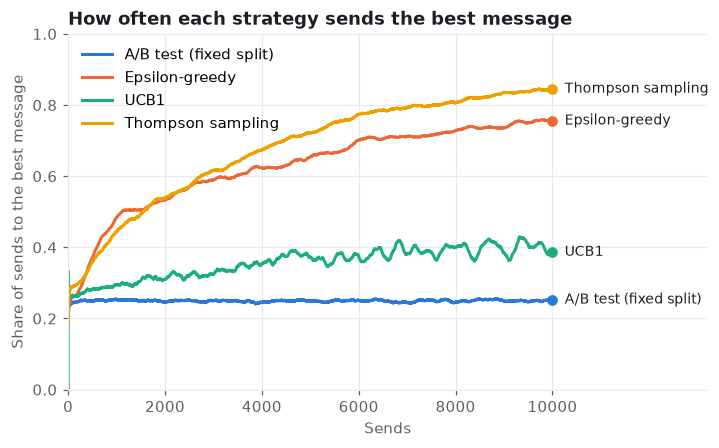

In [12]:
fig, ax = plt.subplots()
for name, res in results.items():
    share = pd.Series(res.share_of_best()).rolling(200, min_periods=1).mean()
    ax.plot(share.index + 1, share, color=style.STRATEGY_COLOURS[name], label=name)
    style.label_line_end(ax, len(share), share.iloc[-1], name, style.STRATEGY_COLOURS[name])
ax.set(title="How often each strategy sends the best message", xlabel="Sends",
       ylabel="Share of sends to the best message")
ax.set_ylim(0, 1)
ax.set_xlim(0, HORIZON * 1.32)
ax.set_xticks(range(0, HORIZON + 1, 2000))
ax.legend(loc="upper left")
plt.show()

The confidence intervals come from `pg.compute_bootci`, which bootstraps the mean across the simulated worlds. On this problem Thompson sampling loses the fewest learners. Epsilon-greedy comes surprisingly close, which is a good reminder to always try the simple baseline, but its 10% random sends are a permanent tax that never goes away. UCB1 explores the most: it keeps checking messages it should have dropped, and loses about twice as many learners as Thompson. My default in practice is Thompson sampling: it's the easiest to get right and it has no knob to tune.

<details>
<summary><b>Under the hood: the UCB1 score</b></summary>

After $t$ total sends, a message sent $n_a$ times with observed rate $\hat p_a$ gets the score

$$\hat p_a + \sqrt{\frac{2 \ln t}{n_a}}.$$

The bonus shrinks as a message is tried more, and grows slowly with time, so no message is ever abandoned completely. Auer, Cesa-Bianchi and Fischer (Auer et al., 2002) proved that this keeps regret growing only logarithmically in $t$.

</details>

## When the A/B test is still the right call

A bandit maximises reward *while* it learns. A fixed-split test maximises *knowledge*. Choose the test when knowledge is the point:

- **You need the size of the effect, not just the winner.** A bandit starves the losing arms, so their estimates stay noisy. And even the winner's naive estimate is biased by the adaptive sampling. Chapter 10 covers how to get honest numbers out of a bandit.
- **The outcome arrives late.** If "came back" really means "still subscribed in 90 days", a bandit has nothing to learn from for three months. Chapter 8 deals with delayed rewards and early proxy signals.
- **Behaviour changes over time.** A message that wins this week might wear out next month. Plain Thompson sampling assumes rates are fixed.
- **You must watch guardrails.** Unsubscribes, complaints, latency. A test with a fixed split gives you clean comparisons on every metric, not just the one the bandit optimises.
- **The decision is big and one-off.** A pricing change you'll ship to everyone deserves the cleaner evidence.

Bandits shine when decisions repeat many times, the reward comes back quickly, and the cost of sending a bad option is real. Reminders, subject lines, recommendations and model routing all fit that pattern.

## Juno: routing lessons between three LLMs

Now the agent version. Juno, Parlo's AI tutor, can run a lesson on one of three LLMs. Larger models complete more lessons but cost more.

In [13]:
models = pd.DataFrame([vars(m) for m in parlo.JUNO_MODELS]).set_index("name")
models["net value per lesson"] = parlo.juno_rewards()
models

,completion_rate,cost,net value per lesson
name,,,
large,0.78,0.020,0.058
medium,0.74,0.006,0.068
small,0.62,0.001,0.061


Each completed lesson is worth \$0.10 to Parlo, so the net value of a lesson is \$0.10 × completion rate − cost. What counts as the "best" model depends on which reward you hand the bandit:

In [14]:
comp_rates = models["completion_rate"].to_numpy()
costs = models["cost"].to_numpy()

by_completion = parlo.simulate(parlo.thompson, comp_rates, 5_000, RUNS, seed=2)
by_value = parlo.simulate(parlo.thompson_with_cost(costs), comp_rates, 5_000, RUNS, seed=2)

def last_share(res):
    counts = np.bincount(res.choices[:, -1000:].ravel(), minlength=3)
    return counts / counts.sum()

pd.DataFrame({"reward = lesson completed": last_share(by_completion),
              "reward = value minus cost": last_share(by_value)},
             index=models.index).style.format("{:.0%}")

,reward = lesson completed,reward = value minus cost
name,,
large,96%,0%
medium,4%,98%
small,0%,1%


In [15]:
nv = parlo.juno_rewards()
glue_num("juno_gain", 1000 * (nv.max() - nv[0]))

Optimise completion alone and the bandit routes almost everything to the large model. Optimise net value and it moves to the medium model. That model completes slightly fewer lessons, but it's worth about **$10 more per 1,000 lessons**. Same algorithm, different reward, different winner.

That's the most important lesson in this chapter: **the bandit optimises exactly the reward you give it.** Choosing the reward is a product decision, not a modelling detail. For agents it usually has to include cost and latency, not just quality.

> **In the wild**
>
> Thompson sampling was born in medicine, not marketing. William R. Thompson proposed it in 1933 (Thompson, 1933) for clinical trials: give more patients the treatment that is *probably* better, in proportion to how likely it is to be better, so fewer patients get the worse one while the trial is still learning. The web rediscovered the idea nearly eighty years later, for the same reason: every send to the worse message is a cost.

## Pitfalls

- **Rewarding the wrong thing.** Clicks aren't lessons, and opens aren't renewals. A bandit will happily find the message that maximises a shallow metric.
- **Too-greedy exploration.** Epsilon-greedy with a tiny $\varepsilon$, or a "pick the leader after 100 sends" rule, can lock onto a lucky loser for good.
- **Peeking at the bandit's estimates as if they were an A/B test.** The sample sizes are adaptive, so naive confidence intervals are wrong (Chapter 10).
- **Ignoring delays.** If rewards arrive late or in batches, a bandit built for instant feedback is actually reasoning about stale data (Chapter 8).
- **No holdout.** Without a group that never sees the bandit, you can't measure the lift the bandit itself created (Chapter 10).

## From four arms to 5,000 orders

Four messages are easy. Now imagine a lifecycle journey of seven emails, where the *order* of the emails matters. Seven emails can be ordered in $7! = 5{,}040$ ways. A fixed A/B test across 5,040 arms would need millions of users before it learned anything.

That's the situation JustAI describes in its public case study with Better Mortgage (JustAI, 2026): a multi-armed bandit treats every send as a fresh decision, stays inside business rules set by Better, optimises for a locked rate, and uses clicks as an early signal while locks trickle in. In a separate journey, application starts rose from 9.25% to 12.08% on about 2,600 homebuyers per arm. I checked that result myself: it gives $z \approx 3.3$, $p \approx 0.001$, and a 95% interval for the lift of roughly 1.2 to 4.5 points. That's real, but wider than the headline suggests.

Getting from four arms to thousands takes three more ideas: delayed and proxy rewards (Chapter 8), context and combinatorial arms (Chapter 9), and a holdout to prove the lift (Chapter 10). We'll rebuild that kind of journey, step by step, in Parlo.

## Exercises

1. **Closer race.** Change "Juno says hi" to 0.106, just above "Streak at risk", and rerun the strategy comparison. Which strategy suffers most, and why?
2. **Tune epsilon.** Try $\varepsilon \in \{0.01, 0.05, 0.2\}$. Plot final regret against $\varepsilon$. Is there a value that beats Thompson sampling here?
3. **Price of a model.** In the Juno example, at what cost per lesson does the large model become the best choice by net value? Check your answer with the simulator.

## Further reading

The Thompson sampling idea is nearly a century old (Thompson, 1933). For a practical modern treatment, see Russo and colleagues (Russo et al., 2018). For inference after adaptive experiments, see Hadad and colleagues (Hadad et al., 2021).